# Visualización de mapas UNet — fold 2 (ownKFold test)

Explora mapas de activación **8×8×1024** (`conv_pw_13_relu`) antes y después del traductor UNet v2:

| Fila | Tensor |
|------|--------|
| 1 | `f_mri` — entrada al UNet (MobileNet MRI congelado) |
| 2 | `f_hat` — salida `TransferUNet_v2(f_mri)` |
| 3 | `\|f_hat − f_mri\|` — magnitud del cambio (donde actúa el UNet) |
| 4 | `f_spect` — referencia SPECT (MobileNet SPECT congelado, mismo corte) |

**Criterio de canales:** top-`k` con mayor `‖f_hat − f_mri‖` (norma Frobenius sobre 8×8 por canal).

**Modelo:** `ownKFold/models/fold2/transfer_fold2.keras`  
**Sujetos:** test de fold 2 (`testFold.txt`, n=36)  
**Rango axial:** z ∈ [78, 112]

In [1]:
from __future__ import annotations

import sys
from functools import lru_cache
from pathlib import Path

import matplotlib.pyplot as plt
import nibabel as nib
import numpy as np
import pandas as pd
import tensorflow as tf

FST_ROOT = Path("/workspace/IL-FST")
sys.path.insert(0, str(FST_ROOT))

from fst.keras_fst_models import build_feature_extractor, load_classifier
from fst.slice_data import map_volume_to_unit_interval, slice_to_rgb

# --- rutas fijas (fold 2 ownKFold) ---
EXP = FST_ROOT / "result" / "fst_clsfeat_mnet2d_v2_z78_112" / "ownKFold"
FOLD = 2
CACHE = FST_ROOT / "data" / "feat_cache_z78_112"
TRANSFER_PATH = EXP / "models" / f"fold{FOLD}" / f"transfer_fold{FOLD}.keras"
SPECT_CKPT = FST_ROOT / "classifiers" / "classifiers_roi_4mm" / "spect" / "model.keras"
SPECT_ROOT = Path("/workspace/IL-CLDM/data_rois/whole_Abeta_4mm")
TEST_LIST = EXP / "models" / f"fold{FOLD}" / "testFold.txt"
PREDICTIONS = EXP / "models" / f"fold{FOLD}" / f"predictions_fold{FOLD}.csv"

Z_MIN, Z_MAX = 78, 112
LABEL_NAME = {0: "Control", 1: "PD"}
ROW_NAMES = ["f_mri (in)", "f_hat (out)", "|f_hat − f_mri|", "f_spect (ref)"]

for g in tf.config.list_physical_devices("GPU"):
    try:
        tf.config.experimental.set_memory_growth(g, True)
    except Exception:
        pass

print("transfer:", TRANSFER_PATH)
print("exists:", TRANSFER_PATH.is_file())
print("spect ckpt:", SPECT_CKPT, SPECT_CKPT.is_file())

2026-09-01 13:53:22.442710: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-09-01 13:53:22.464752: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1788270802.488264  162941 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1788270802.495938  162941 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1788270802.516000  162941 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking 

transfer: /workspace/IL-FST/result/fst_clsfeat_mnet2d_v2_z78_112/ownKFold/models/fold2/transfer_fold2.keras
exists: True
spect ckpt: /workspace/IL-FST/classifiers/classifiers_roi_4mm/spect/model.keras True


In [2]:
# --- carga de datos y modelos ---
test_ids = {ln.strip() for ln in TEST_LIST.read_text().splitlines() if ln.strip()}

full_idx = pd.read_csv(CACHE / "index.csv", dtype={"subject_id": str})
full_idx["global_row"] = np.arange(len(full_idx))
test_idx = full_idx[
    full_idx["subject_id"].isin(test_ids)
    & (full_idx["slice_idx"] >= Z_MIN)
    & (full_idx["slice_idx"] <= Z_MAX)
].copy().reset_index(drop=True)

Fm = np.load(CACHE / "f_mri.npy", mmap_mode="r")

preds = pd.read_csv(PREDICTIONS, dtype={"subject_id": str})
subj_summary = (
    preds.groupby("subject_id", as_index=False)
    .agg(label=("label", "first"), prob=("prob", "first"), pred=("pred", "first"), stratum=("stratum", "first"))
    .sort_values("subject_id")
)
print(f"fold {FOLD} test: {len(test_ids)} sujetos, {len(test_idx)} cortes (z={Z_MIN}..{Z_MAX})")
subj_summary.head(10)

fold 2 test: 36 sujetos, 1260 cortes (z=78..112)


,subject_id,label,prob,pred,stratum
0,3105,1,0.994001,1,pd_nhy2
1,3113,1,0.948719,1,pd_nhy1
2,3115,0,0.878194,1,control
3,3120,1,0.546929,1,pd_nhy2
4,3124,1,0.986426,1,pd_nhy1
5,3128,1,0.205836,0,pd_nhy2
6,3167,1,0.874186,1,pd_nhy1
7,3168,1,0.977800,1,pd_nhy2
8,3171,0,0.001395,0,control
9,3305,1,0.850048,1,pd_nhy1


In [3]:
xfer = tf.keras.models.load_model(str(TRANSFER_PATH), compile=False)
spect_feat = build_feature_extractor(load_classifier(SPECT_CKPT), name="spect_feat_fold2_vis")
print("UNet:", xfer.name, "params:", xfer.count_params())
print("SPECT extractor:", spect_feat.name)


@lru_cache(maxsize=64)
def _load_spect_volume(subject_id: str) -> np.ndarray:
    path = SPECT_ROOT / f"{subject_id}.nii.gz"
    if not path.is_file():
        raise FileNotFoundError(path)
    vol = np.asarray(nib.load(str(path)).get_fdata(), dtype=np.float32)
    return map_volume_to_unit_interval(vol, "spect")


def extract_f_spect(subject_id: str, slice_idx: int) -> np.ndarray:
    vol = _load_spect_volume(subject_id)
    tile = slice_to_rgb(vol[:, :, int(slice_idx)])[None]
    return spect_feat(tile, training=False).numpy()[0]


def compute_maps(global_row: int, subject_id: str, slice_idx: int):
    f_mri = np.asarray(Fm[int(global_row)], dtype=np.float32)
    f_hat = xfer(f_mri[None], training=False).numpy()[0]
    delta = f_hat - f_mri
    f_spect = extract_f_spect(subject_id, slice_idx)
    return f_mri, f_hat, delta, f_spect


def channel_scores(delta: np.ndarray) -> np.ndarray:
    """Norma Frobenius por canal sobre el mapa 8×8."""
    return np.sqrt((delta ** 2).sum(axis=(0, 1)))


def slice_score(delta: np.ndarray) -> float:
    return float(np.sqrt((delta ** 2).sum()))


def top_channels(delta: np.ndarray, k: int = 16) -> tuple[np.ndarray, np.ndarray]:
    scores = channel_scores(delta)
    order = np.argsort(scores)[::-1][:k]
    return order, scores[order]

I0000 00:00:1788270816.524668  162941 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 178 MB memory:  -> device: 0, name: NVIDIA RTX A2000 12GB, pci bus id: 0000:1a:00.0, compute capability: 8.6


UNet: fst_transfer_v2 params: 2390656
SPECT extractor: spect_feat_fold2_vis


In [4]:
def plot_channel_grid(
    f_mri,
    f_hat,
    delta,
    f_spect,
    chans,
    scores,
    *,
    title: str,
    k: int | None = None,
    cmap_act: str = "magma",
    cmap_delta: str = "inferno",
):
    k = k or len(chans)
    chans = np.asarray(chans[:k])
    scores = np.asarray(scores[:k])

    maps_act = [f_mri, f_hat, f_spect]
    vmax_act = max(m[:, :, chans].max() for m in maps_act)
    vmax_act = max(vmax_act, 1e-6)
    vmax_delta = max(np.abs(delta[:, :, chans]).max(), 1e-8)

    fig, axes = plt.subplots(4, k, figsize=(1.35 * k, 5.2), squeeze=False)
    row_maps = [
        (f_mri, cmap_act, 0.0, vmax_act),
        (f_hat, cmap_act, 0.0, vmax_act),
        (np.abs(delta), cmap_delta, 0.0, vmax_delta),
        (f_spect, cmap_act, 0.0, vmax_act),
    ]

    for r, (m, cmap, vmin, vmax) in enumerate(row_maps):
        for c, ch in enumerate(chans):
            ax = axes[r, c]
            ax.imshow(m[:, :, ch], vmin=vmin, vmax=vmax, cmap=cmap, interpolation="nearest")
            ax.set_xticks([])
            ax.set_yticks([])
            if r == 0:
                ax.set_title(f"c{ch}\n‖Δ‖={scores[c]:.3f}", fontsize=8)
            if c == 0:
                ax.set_ylabel(ROW_NAMES[r], fontsize=9)

    fig.suptitle(title, fontsize=11, y=1.02)
    fig.tight_layout()
    return fig


def show_slice(global_row: int, subject_id: str, slice_idx: int, label: int, k: int = 16, prob: float | None = None):
    f_mri, f_hat, delta, f_spect = compute_maps(global_row, subject_id, slice_idx)
    chans, scores = top_channels(delta, k=k)
    prob_txt = f"  P(PD)={prob:.3f}" if prob is not None else ""
    title = (
        f"fold {FOLD} | {subject_id} z={slice_idx} | {LABEL_NAME[int(label)]}{prob_txt} | "
        f"‖Δ‖_slice={slice_score(delta):.3f} | top-{k} canales por ‖Δ‖"
    )
    return plot_channel_grid(f_mri, f_hat, delta, f_spect, chans, scores, title=title, k=k)

## 1. Ranking de cortes por sujeto (test fold 2)

Para cada sujeto del test, ordenamos los cortes z por `‖f_hat − f_mri‖` global (8×8×1024). Así se elige el corte donde el UNet actúa con más intensidad.

In [5]:
def rank_slices_for_subject(subject_id: str, top_n: int = 5) -> pd.DataFrame:
    rows = test_idx[test_idx["subject_id"] == subject_id]
    scored = []
    for r in rows.itertuples(index=False):
        f_mri = np.asarray(Fm[int(r.global_row)], dtype=np.float32)
        f_hat = xfer(f_mri[None], training=False).numpy()[0]
        scored.append(
            {
                "subject_id": r.subject_id,
                "slice_idx": int(r.slice_idx),
                "label": int(r.label),
                "global_row": int(r.global_row),
                "delta_norm": slice_score(f_hat - f_mri),
            }
        )
    return pd.DataFrame(scored).sort_values("delta_norm", ascending=False).head(top_n)


# ejemplo: sujeto con predicción correcta alta confianza
example_sid = subj_summary.loc[subj_summary["prob"].idxmax(), "subject_id"]
print("Sujeto ejemplo:", example_sid)
rank_slices_for_subject(example_sid)

Sujeto ejemplo: 3789


I0000 00:00:1788270831.796703  162941 cuda_dnn.cc:529] Loaded cuDNN version 90300
2026-09-01 13:53:52.114261: W external/local_xla/xla/tsl/framework/bfc_allocator.cc:310] Allocator (GPU_0_bfc) ran out of memory trying to allocate 171.95MiB with freed_by_count=0. The caller indicates that this is not a failure, but this may mean that there could be performance gains if more memory were available.
2026-09-01 13:53:52.190949: W external/local_xla/xla/tsl/framework/bfc_allocator.cc:310] Allocator (GPU_0_bfc) ran out of memory trying to allocate 171.88MiB with freed_by_count=0. The caller indicates that this is not a failure, but this may mean that there could be performance gains if more memory were available.
2026-09-01 13:53:52.271496: W external/local_xla/xla/tsl/framework/bfc_allocator.cc:310] Allocator (GPU_0_bfc) ran out of memory trying to allocate 327.06MiB with freed_by_count=0. The caller indicates that this is not a failure, but this may mean that there could be performance gain

,subject_id,slice_idx,label,global_row,delta_norm
7,3789,85,1,3822,61.223049
6,3789,84,1,3821,60.116508
5,3789,83,1,3820,49.903587
24,3789,102,1,3839,47.345665
8,3789,86,1,3823,46.484863


## 2. Grid 4×k — un corte del test fold 2

Filas: `f_mri` | `f_hat` | `|Δ|` | `f_spect`. Columnas: top-`k` canales con mayor `‖Δ‖`.

Cambia `SUBJECT_ID`, `SLICE_Z` y `K` en la celda siguiente.

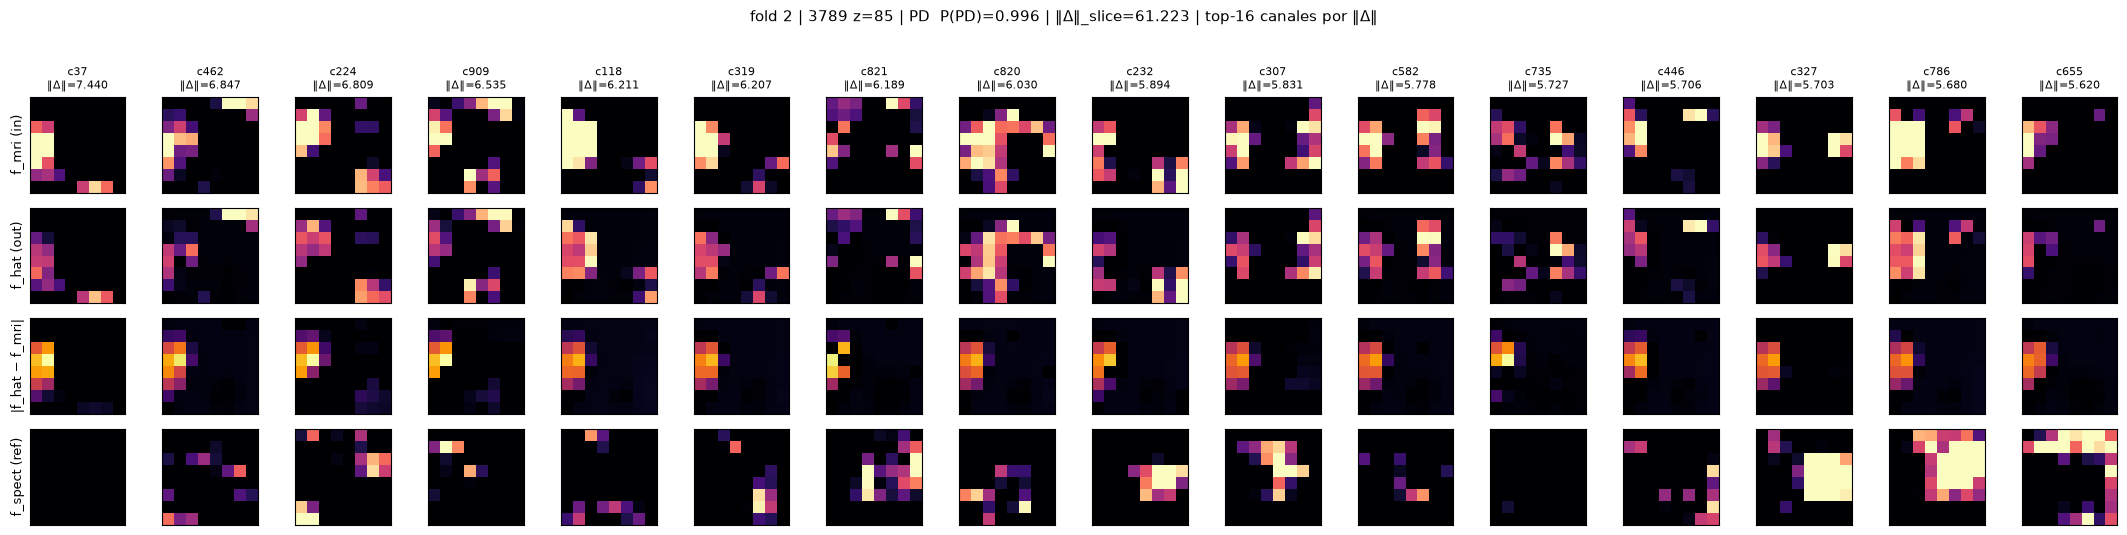

In [6]:
# --- parámetros de visualización ---
SUBJECT_ID = example_sid          # ID del test fold 2
SLICE_Z = int(rank_slices_for_subject(SUBJECT_ID, top_n=1).iloc[0]["slice_idx"])
K = 16

row = test_idx[(test_idx["subject_id"] == SUBJECT_ID) & (test_idx["slice_idx"] == SLICE_Z)].iloc[0]
prob = float(subj_summary.loc[subj_summary["subject_id"] == SUBJECT_ID, "prob"].iloc[0])

fig = show_slice(int(row.global_row), SUBJECT_ID, SLICE_Z, int(row.label), k=K, prob=prob)
plt.show()

## 3. Panel de casos representativos (test fold 2)

Muestra el corte de máximo `‖Δ‖` para seis sujetos: mejor correcto / peor incorrecto por estrato (Control, PD NHY1, PD NHY2), usando las predicciones de fold 2.

In [7]:
STAGE_MAP = {"control": "Control", "pd_nhy1": "PD NHY1", "pd_nhy2": "PD NHY2"}


def pick_representative_cases() -> pd.DataFrame:
    m = subj_summary.copy()
    m["correct"] = m["pred"] == m["label"]
    m["conf_true"] = np.where(m["label"] == 1, m["prob"], 1.0 - m["prob"])
    rows = []
    for stratum, stage in STAGE_MAP.items():
        pool = m[m["stratum"] == stratum]
        for kind, correct in (("best_correct", True), ("worst_incorrect", False)):
            sub = pool[pool["correct"] == correct]
            if sub.empty:
                continue
            pick = sub.nlargest(1, "conf_true").iloc[0] if correct else sub.nsmallest(1, "conf_true").iloc[0]
            top = rank_slices_for_subject(pick["subject_id"], top_n=1).iloc[0]
            rows.append(
                {
                    "panel": f"{stage} / {kind}",
                    "subject_id": pick["subject_id"],
                    "label": int(pick["label"]),
                    "prob": float(pick["prob"]),
                    "pred": int(pick["pred"]),
                    "slice_idx": int(top["slice_idx"]),
                    "global_row": int(top["global_row"]),
                    "delta_norm": float(top["delta_norm"]),
                }
            )
    return pd.DataFrame(rows)


cases = pick_representative_cases()
cases

,panel,subject_id,label,prob,pred,slice_idx,global_row,delta_norm
0,Control / best_correct,3171,0,0.001395,0,79,1051,404.231537
1,Control / worst_incorrect,3115,0,0.878194,1,98,300,140.805984
2,PD NHY1 / best_correct,3124,1,0.986426,1,81,423,48.987434
3,PD NHY1 / worst_incorrect,3830,1,0.011263,0,105,4367,307.517395
4,PD NHY2 / best_correct,3789,1,0.995999,1,85,3822,61.223049
5,PD NHY2 / worst_incorrect,3128,1,0.205836,0,104,586,283.758667


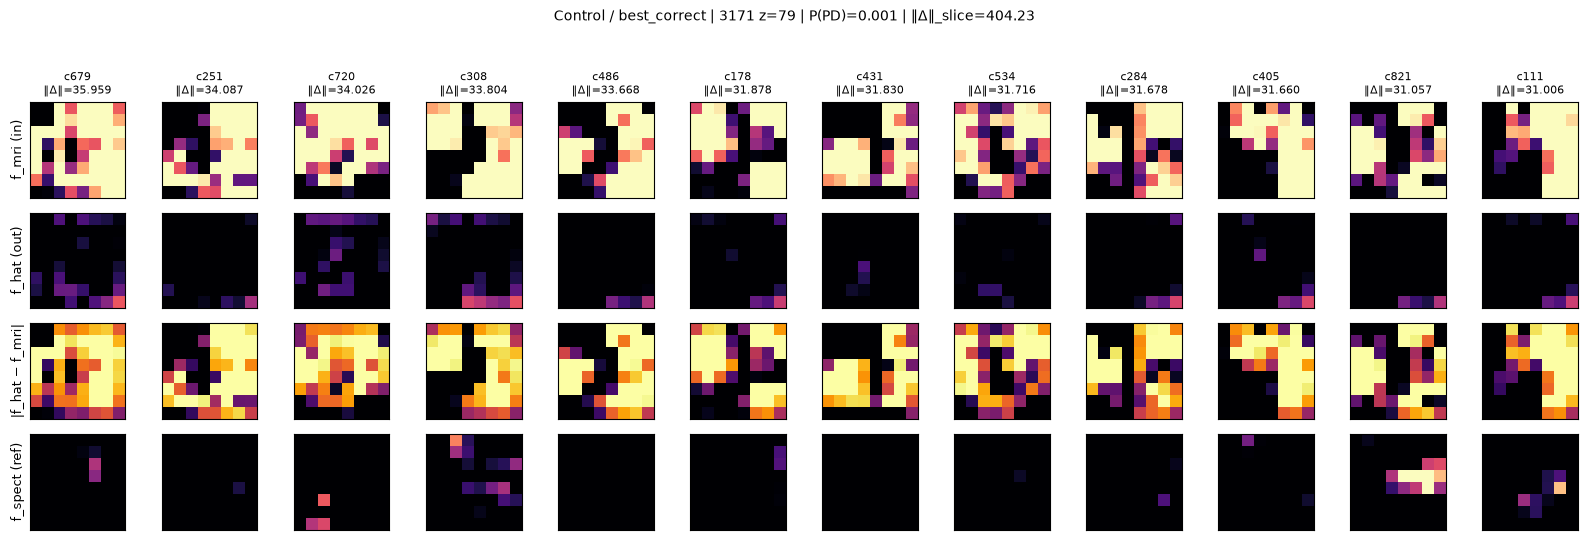

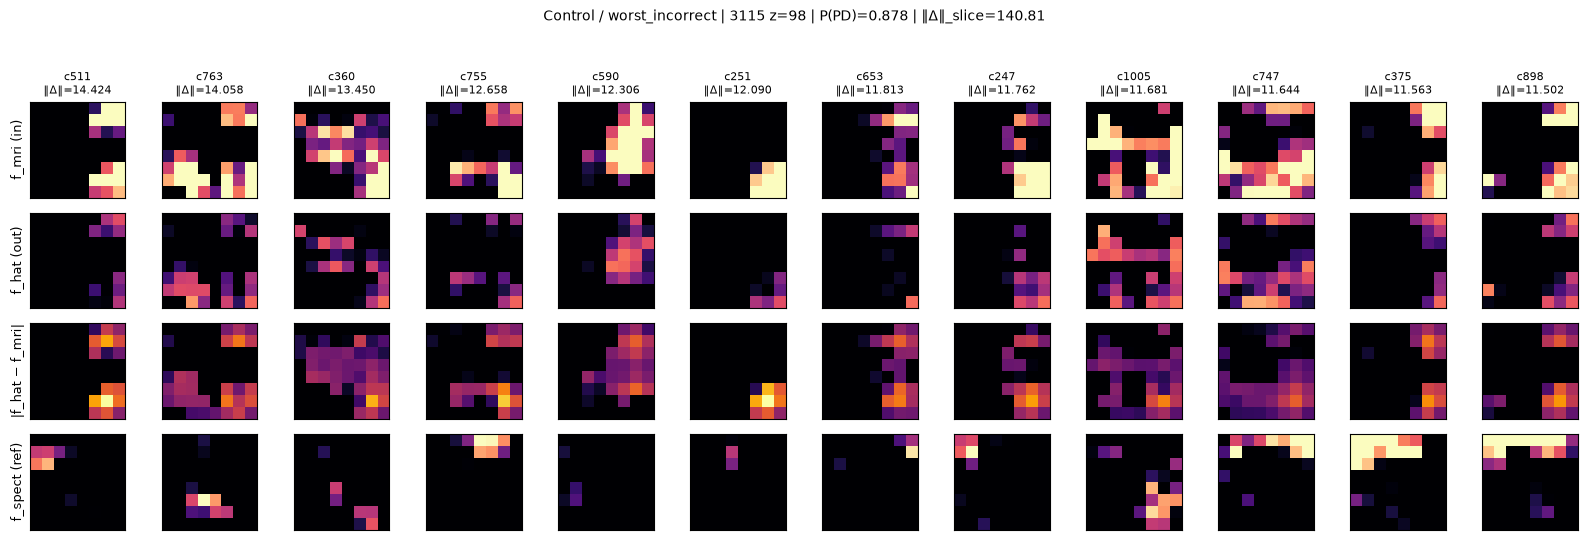

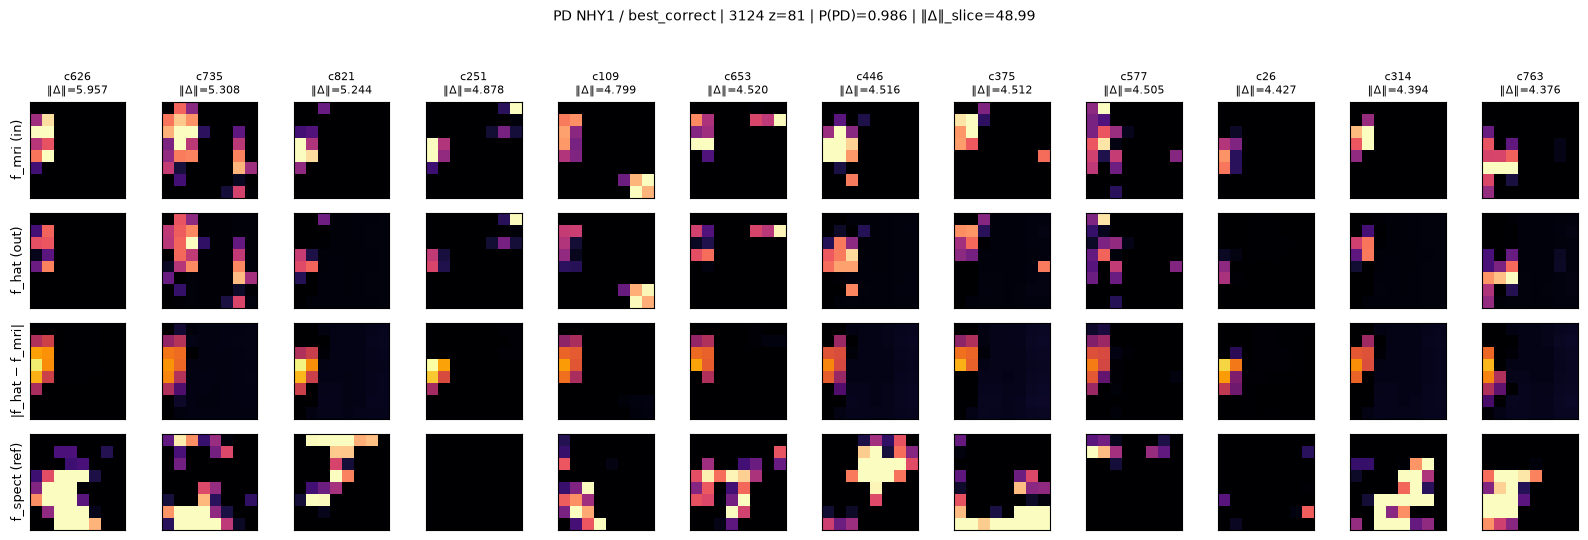

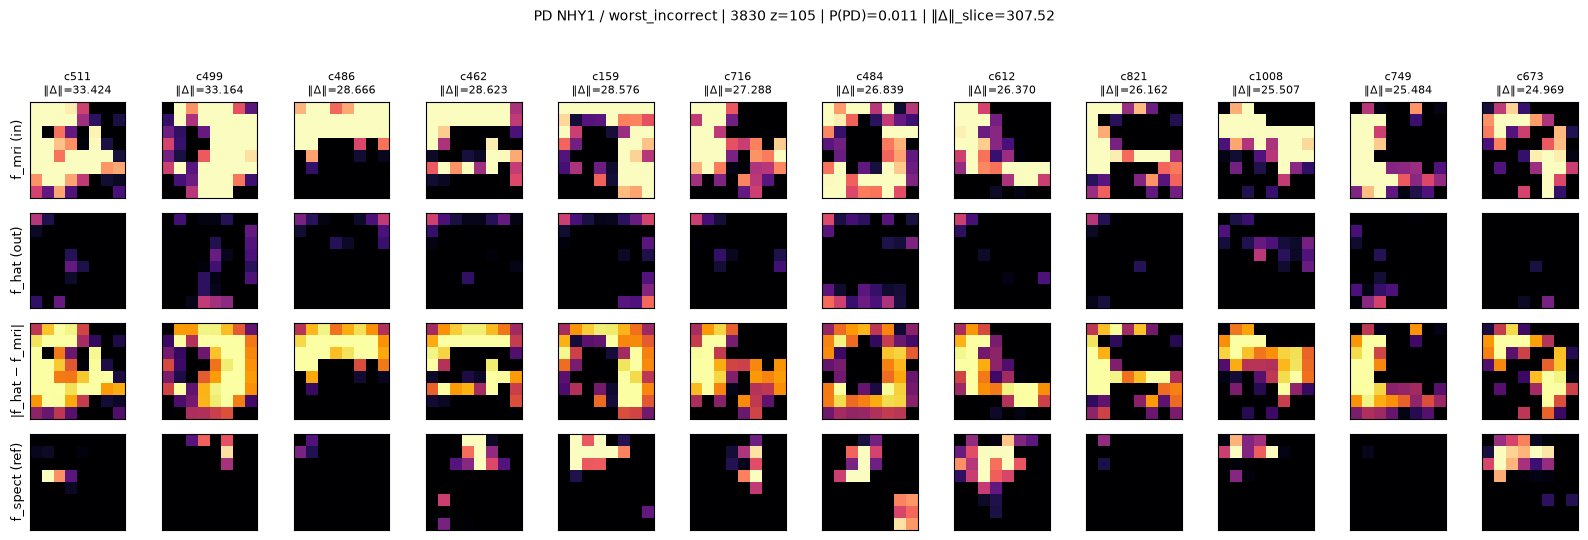

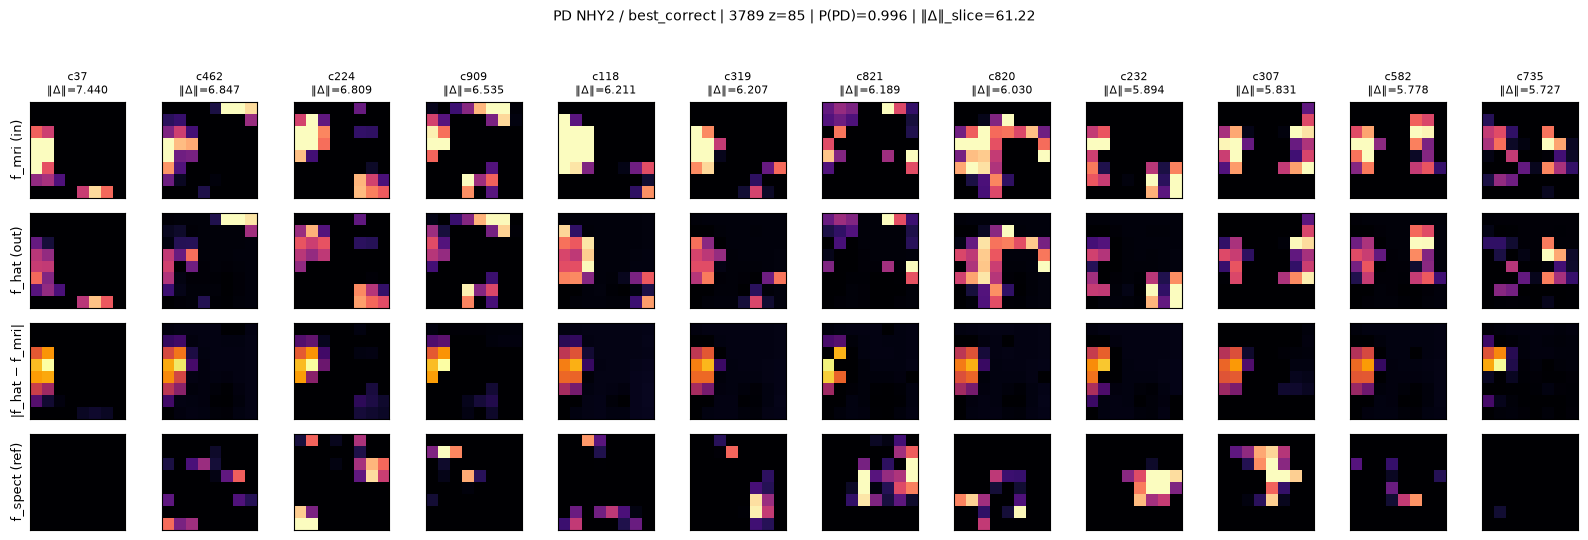

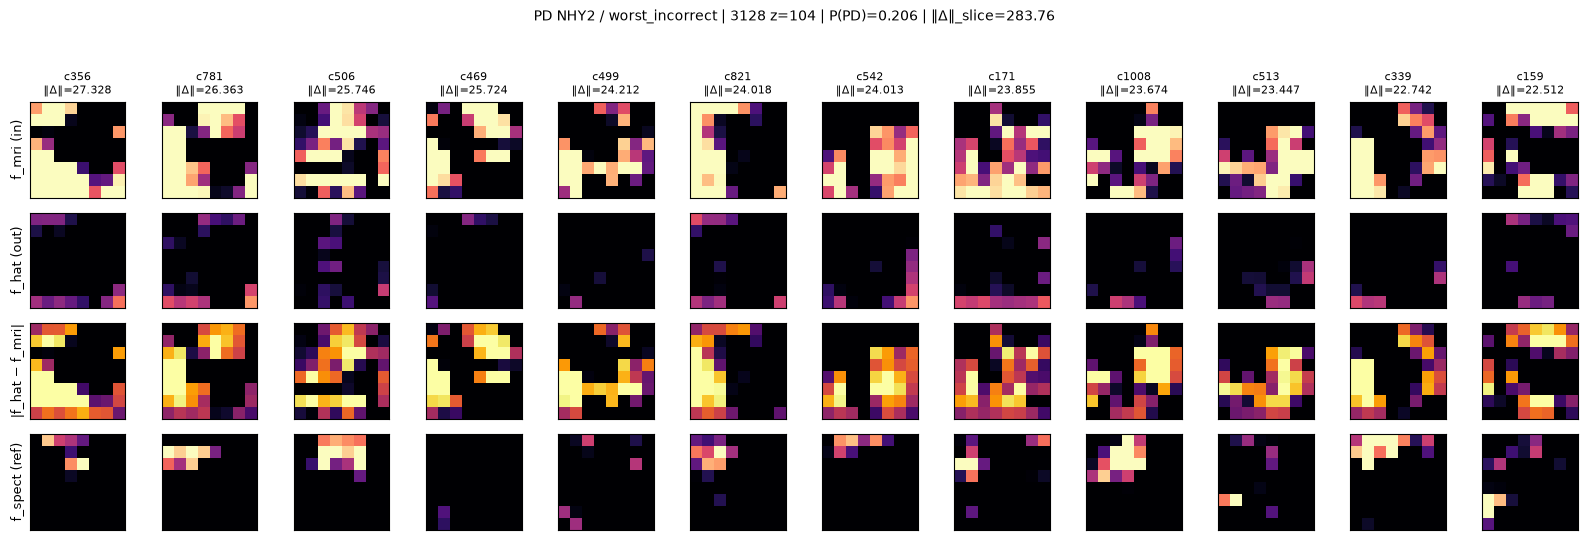

In [8]:
for r in cases.itertuples(index=False):
    fig = show_slice(
        r.global_row,
        r.subject_id,
        r.slice_idx,
        r.label,
        k=12,
        prob=r.prob,
    )
    fig.suptitle(
        f"{r.panel} | {r.subject_id} z={r.slice_idx} | P(PD)={r.prob:.3f} | ‖Δ‖_slice={r.delta_norm:.2f}",
        fontsize=10,
        y=1.03,
    )
    plt.show()

## 4. Explorador interactivo (opcional)

Si `ipywidgets` está disponible, usa el selector para recorrer sujetos del test fold 2 y cortes z.

In [ ]:
try:
    import ipywidgets as widgets
    from IPython.display import clear_output, display

    subject_options = sorted(test_idx["subject_id"].unique())

    w_subj = widgets.Dropdown(options=subject_options, description="Sujeto:")
    w_z = widgets.IntSlider(min=Z_MIN, max=Z_MAX, step=1, description="z:")
    w_k = widgets.IntSlider(min=4, max=32, step=4, value=16, description="top-k:")
    w_btn = widgets.Button(description="Visualizar", button_style="primary")
    out = widgets.Output()

    def _refresh_z_options(*_):
        zs = sorted(test_idx.loc[test_idx["subject_id"] == w_subj.value, "slice_idx"].astype(int).unique())
        if zs:
            w_z.min, w_z.max = zs[0], zs[-1]
            w_z.value = zs[len(zs) // 2]
            w_z.step = 1

    def _on_click(_):
        with out:
            clear_output(wait=True)
            row = test_idx[(test_idx["subject_id"] == w_subj.value) & (test_idx["slice_idx"] == w_z.value)]
            if row.empty:
                print(f"No hay corte z={w_z.value} para {w_subj.value} en test fold {FOLD}")
                return
            row = row.iloc[0]
            prob = float(subj_summary.loc[subj_summary["subject_id"] == w_subj.value, "prob"].iloc[0])
            fig = show_slice(int(row.global_row), w_subj.value, int(w_z.value), int(row.label), k=w_k.value, prob=prob)
            plt.show()

    w_subj.observe(_refresh_z_options, names="value")
    _refresh_z_options()
    w_btn.on_click(_on_click)

    display(widgets.VBox([widgets.HBox([w_subj, w_z, w_k, w_btn]), out]))
except ImportError:
    print("ipywidgets no instalado — usa las celdas anteriores con SUBJECT_ID / SLICE_Z.")